# Выявление аномалий (Anomaly Detection)

**Цели:**
1. Понять разницу между простыми статистическими методами (Z-score, IQR) и многомерными (Elliptic Envelope).
2. Увидеть, как работают методы на основе плотности (k-NN, LOF) на данных с разной плотностью кластеров.
3. Познакомиться с ансамблями деревьев (Isolation Forest) и методом опорных векторов (One-Class SVM).
4. Научиться оценивать качество детектора при сильном дисбалансе классов (PR-AUC, F1).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs, make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.metrics import classification_report, precision_recall_curve, auc, f1_score

plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)

## Часть 1. Статистические методы: Z-score, IQR и Elliptic Envelope

### 1.1. Z-score и IQR (на 1D данных)
Сгенерируем нормальное распределение и добавим несколько явных выбросов.

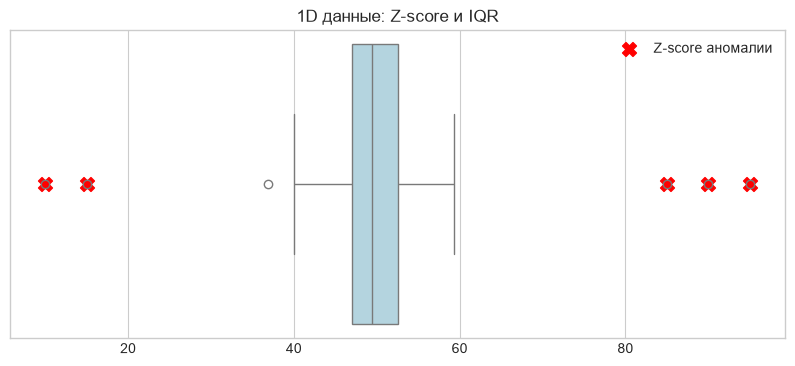

Z-score нашел: 5 аномалий
IQR нашел:    6 аномалий


In [2]:
# Генерируем данные: 100 нормальных + 5 выбросов
np.random.seed(42)
X_normal = np.random.normal(loc=50, scale=5, size=100)
X_outliers = np.array([10, 15, 85, 90, 95])
X_1d = np.concatenate([X_normal, X_outliers]).reshape(-1, 1)

# 1. Z-score
mean = X_1d.mean()
std = X_1d.std()
z_scores = np.abs((X_1d - mean) / std)
outliers_z = X_1d[z_scores > 3]

# 2. IQR
Q1 = np.percentile(X_1d, 25)
Q3 = np.percentile(X_1d, 75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers_iqr = X_1d[(X_1d < lower_bound) | (X_1d > upper_bound)]

plt.figure(figsize=(10, 4))
sns.boxplot(x=X_1d.ravel(), color='lightblue')
plt.scatter(outliers_z, np.zeros(len(outliers_z)), color='red', s=100, label='Z-score аномалии', marker='X')
plt.title('1D данные: Z-score и IQR')
plt.legend()
plt.show()

print(f"Z-score нашел: {len(outliers_z)} аномалий")
print(f"IQR нашел:    {len(outliers_iqr)} аномалий")

**Обсуждение:** Z-score предполагает строго нормальное распределение. IQR (ящик с усами) работает лучше, если данные скошены, так как опирается на квантили. Но оба метода смотрят на каждый признак отдельно.

### 1.2. Elliptic Envelope (многомерные данные)
Посмотрим на 2D данные, где признаки коррелированы. Z-score не поймет, что точка (5, 5) — нормальная для этого распределения, а точка (10, 10) — аномалия, потому что смотрит на каждую ось отдельно. Elliptic Envelope учитывает ковариацию.

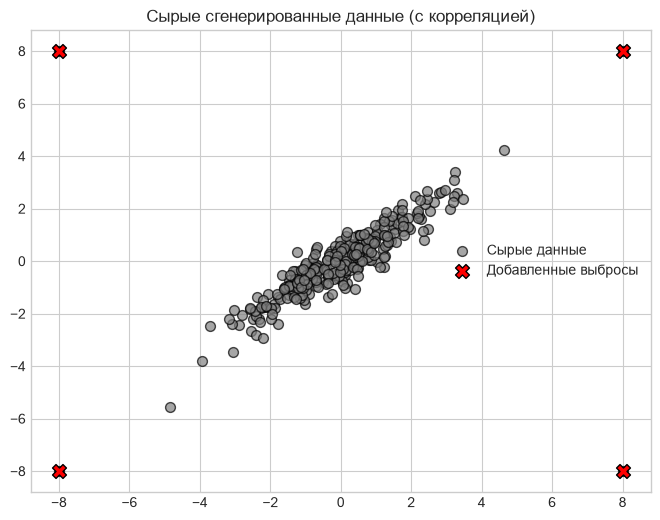

In [10]:
# Генерируем коррелированные данные
X_corr, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=1.5, random_state=42)
X_corr[:, 1] = X_corr[:, 0] * 0.8 + np.random.normal(0, 0.5, 300) # Добавляем корреляцию

# Добавляем аномалии (выбросы в стороне)
outliers = np.array([[8, 8], [-8, -8], [8, -8], [-8, 8]])
X_corr_with_outliers = np.vstack([X_corr, outliers])

# Визуализация сырых данных
plt.figure(figsize=(8, 6))
plt.scatter(X_corr_with_outliers[:, 0], X_corr_with_outliers[:, 1],
            color='gray', edgecolor='k', s=50, alpha=0.7, label='Сырые данные')

# Выделим добавленные аномалии, чтобы было видно, где они
plt.scatter(outliers[:, 0], outliers[:, 1],
            color='red', edgecolor='k', s=100, marker='X', label='Добавленные выбросы')
plt.title('Сырые сгенерированные данные (с корреляцией)')
plt.legend()
plt.grid(True)
plt.show()

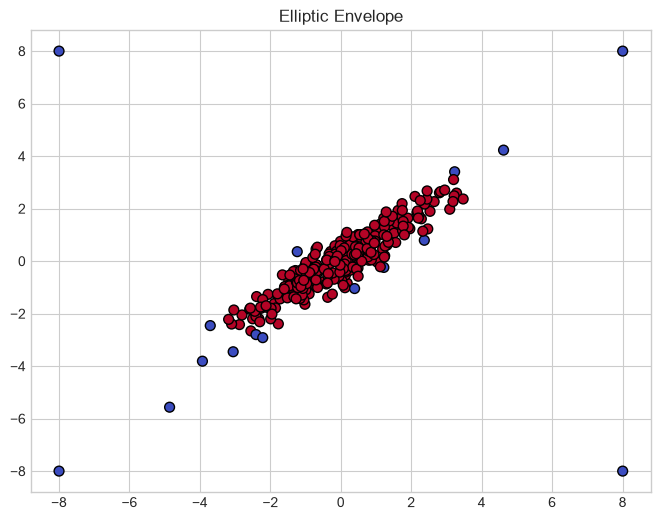

In [11]:
# Обучаем Elliptic Envelope (MCD)
ee = EllipticEnvelope(contamination=0.05, random_state=42)
ee.fit(X_corr_with_outliers)
y_pred_ee = ee.predict(X_corr_with_outliers) # 1 - норма, -1 - аномалия

plt.figure(figsize=(8, 6))
plt.scatter(X_corr_with_outliers[:, 0], X_corr_with_outliers[:, 1], 
            c=y_pred_ee, cmap='coolwarm', edgecolor='k', s=50)
plt.title('Elliptic Envelope')
plt.grid(True)
plt.show()

## Часть 2. Методы расстояний и плотности: k-NN и LOF

Сгенерируем данные с **разной плотностью** кластеров. Один кластер плотный, другой — разреженный. Добавим аномалии.
**Проблема:** Z-score или простые методы тут не сработают, так как у кластеров разные масштабы.

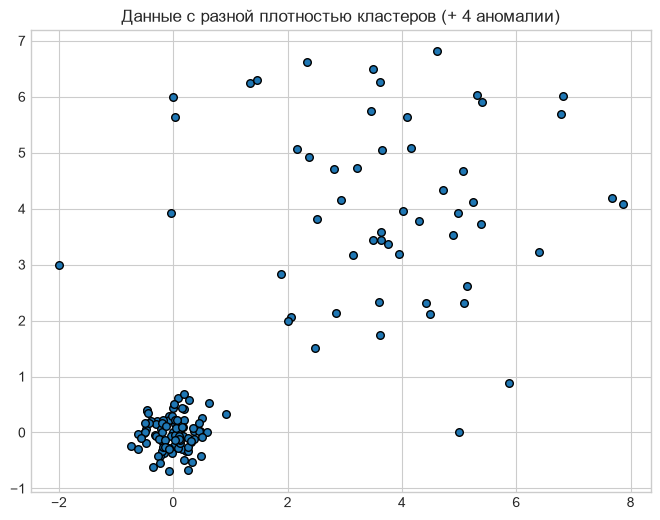

In [4]:
# Плотный кластер (100 точек)
X_dense = np.random.normal(loc=(0, 0), scale=0.3, size=(100, 2))
# Разреженный кластер (50 точек)
X_sparse = np.random.normal(loc=(4, 4), scale=1.5, size=(50, 2))
# Аномалии
X_out = np.array([[2, 2], [-2, 3], [5, 0], [0, 6]])

X_mixed = np.vstack([X_dense, X_sparse, X_out])

plt.figure(figsize=(8, 6))
plt.scatter(X_mixed[:, 0], X_mixed[:, 1], s=30, edgecolor='k')
plt.title('Данные с разной плотностью кластеров (+ 4 аномалии)')
plt.show()

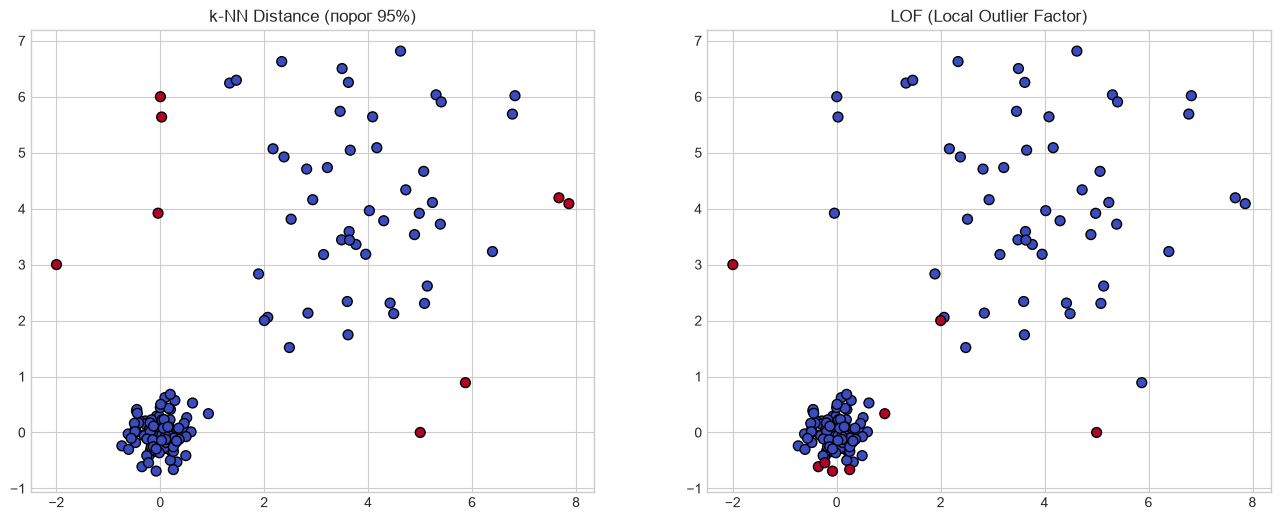

In [5]:
# 2.1. k-NN Distance
nn = NearestNeighbors(n_neighbors=10)
nn.fit(X_mixed)
distances, _ = nn.kneighbors(X_mixed)
knn_score = distances.mean(axis=1) # среднее расстояние до 10 соседей
threshold_knn = np.quantile(knn_score, 0.95)
labels_knn = (knn_score > threshold_knn).astype(int) # 1 = аномалия

# 2.2. LOF (Local Outlier Factor)
lof = LocalOutlierFactor(n_neighbors=10, contamination=0.05)
labels_lof = lof.fit_predict(X_mixed) # 1 = норма, -1 = аномалия
labels_lof_bin = (labels_lof == -1).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].scatter(X_mixed[:, 0], X_mixed[:, 1], c=labels_knn, cmap='coolwarm', edgecolor='k', s=50)
axes[0].set_title('k-NN Distance (порог 95%)')

axes[1].scatter(X_mixed[:, 0], X_mixed[:, 1], c=labels_lof_bin, cmap='coolwarm', edgecolor='k', s=50)
axes[1].set_title('LOF (Local Outlier Factor)')
plt.show()

**Обсуждение:**
* Посмотрите на k-NN (левый график). Он пометил как аномалии много точек в разреженном кластере, потому что расстояние до соседей там в принципе большое.
* LOF (правый график) справился лучше - он смотрит на локальную плотность: если точка окружена такими же разреженными соседями — она нормальная. Аномалия — это когда точка сильно разреженнее, чем её соседи.

## Часть 3. Isolation Forest и One-Class SVM
Сгенерируем 2D данные для визуализации этих двух алгоритмов.

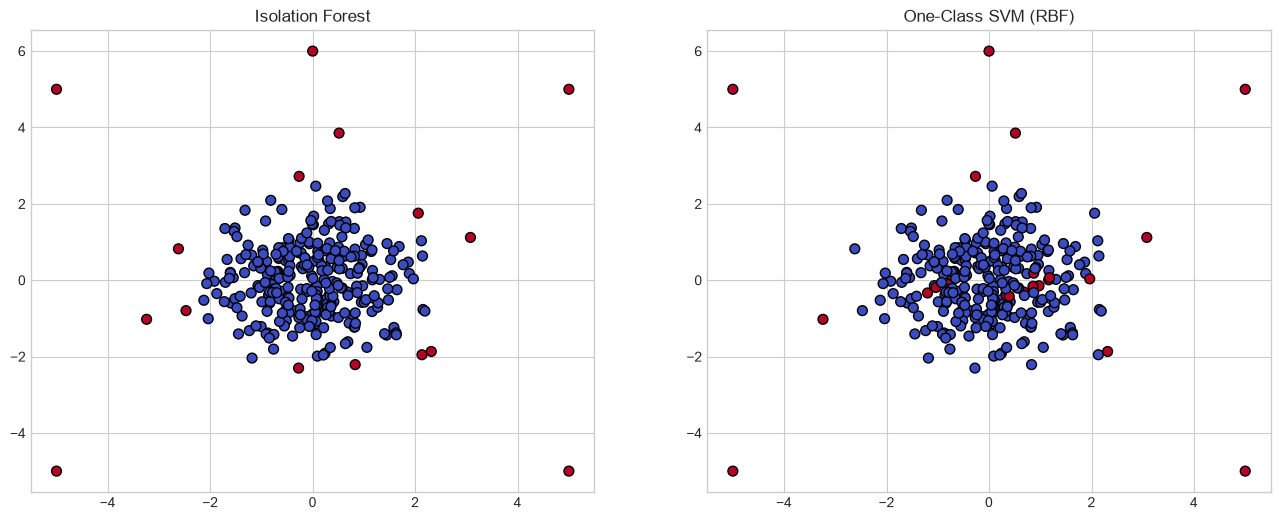

In [6]:
X_iforest, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=1.0, random_state=42)
X_outliers_if = np.array([[5, 5], [-5, -5], [5, -5], [-5, 5], [0, 6]])
X_if = np.vstack([X_iforest, X_outliers_if])

# Isolation Forest
iso = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
labels_iso = iso.fit_predict(X_if)
labels_iso_bin = (labels_iso == -1).astype(int)

# One-Class SVM
ocsvm = OneClassSVM(kernel='rbf', gamma='auto', nu=0.05)
labels_ocsvm = ocsvm.fit_predict(X_if)
labels_ocsvm_bin = (labels_ocsvm == -1).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].scatter(X_if[:, 0], X_if[:, 1], c=labels_iso_bin, cmap='coolwarm', edgecolor='k', s=50)
axes[0].set_title('Isolation Forest')

axes[1].scatter(X_if[:, 0], X_if[:, 1], c=labels_ocsvm_bin, cmap='coolwarm', edgecolor='k', s=50)
axes[1].set_title('One-Class SVM (RBF)')
plt.show()

**Обсуждение:**
* **Isolation Forest** строит случайные деревья. Аномалии изолируются быстрее (оказываются на меньшей глубине). Это стандарт для больших данных.
* **One-Class SVM** строит сложную границу (благодаря ядру RBF - радиальной базисной функции, Radial Basis Function) вокруг нормальных данных. Он хорош для малых выборок.

## Часть 4. Оценка качества при сильном дисбалансе
В реальных задачах аномалий очень мало (1-5%). Оценивать их через Accuracy нельзя. Используем PR-AUC и F1.

Сгенерируем датасет через `make_classification` с `weights=[0.95, 0.05]` (95% норма, 5% аномалии).

PR-AUC: 0.144

Лучший порог по F1: 0.477
              precision    recall  f1-score   support

       Норма       0.97      0.84      0.90       946
    Аномалия       0.16      0.52      0.24        54

    accuracy                           0.82      1000
   macro avg       0.56      0.68      0.57      1000
weighted avg       0.92      0.82      0.86      1000



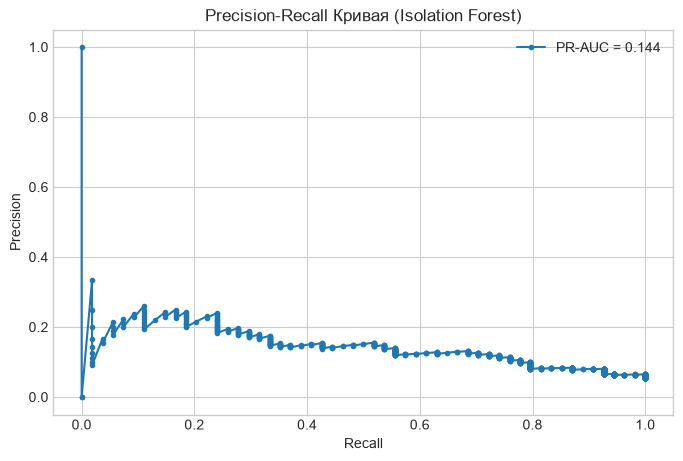

In [7]:
X_syn, y_syn = make_classification(
    n_samples=1000, n_features=10, n_informative=5, n_redundant=2,
    weights=[0.95, 0.05], random_state=42
)
X_syn_scaled = StandardScaler().fit_transform(X_syn)

# Обучаем Isolation Forest
iso_eval = IsolationForest(contamination=0.05, random_state=42)
iso_eval.fit(X_syn_scaled)
# Возвращаем скоры: чем меньше, тем аномальнее
scores_iso = -iso_eval.score_samples(X_syn_scaled)

# Оцениваем качество
# Используем PR-AUC (Precision-Recall AUC), так как классы несбалансированы
precision, recall, _ = precision_recall_curve(y_syn, scores_iso)
pr_auc = auc(recall, precision)

print(f"PR-AUC: {pr_auc:.3f}")

# Подбираем порог по F1 (в реальности порог подбирают на validation)
f1_scores = []
for t in np.percentile(scores_iso, np.arange(80, 100, 1)):
    y_pred = (scores_iso > t).astype(int)
    f1_scores.append(f1_score(y_syn, y_pred))

best_threshold = np.percentile(scores_iso, 80 + np.argmax(f1_scores))
y_pred_best = (scores_iso > best_threshold).astype(int)

print(f"\nЛучший порог по F1: {best_threshold:.3f}")
print(classification_report(y_syn, y_pred_best, target_names=['Норма', 'Аномалия']))

plt.figure(figsize=(8, 5))
plt.plot(recall, precision, marker='.', label=f'PR-AUC = {pr_auc:.3f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Кривая (Isolation Forest)')
plt.legend()
plt.grid(True)
plt.show()